# Part 7: From uplift to dollars: stop discounting clients who were never leaving

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

So far the goal has been to save the most **clients**. A bank is judged in money. Clients differ enormously in size, and a pricing concession is not free: it is paid by every treated client who stays, including the ones who were never going to leave.

**In this notebook**

1. The net value of a pricing call, and where the formula comes from.
2. Four clients where the highest uplift is not the best call, and the biggest client loses money.
3. A new cycle: rank this cycle's 6,000 flagged clients by churn risk, by uplift, and by net value, and count the dollars.
4. The profit curve, and why the model's dollar estimates are too optimistic.

Amounts are illustrative: revenue at risk is two years of revenue, the concession is 3% of it, and each negotiation costs $10,000 of RM and pricing-desk time.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_series import SERIES_SEED, analysis_pool, generate_bank
from uplift_series import plotting as P
from uplift_series.economics import (CONCESSION_RATE, RM_COST, apply_uplift_calibration,
                                     fit_uplift_calibration, net_value, profit_curve,
                                     revenue_at_risk, true_net_value)
from uplift_series.evaluation import uplift_by_bin
from uplift_series.modeling import TLearner, split_pool

P.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

history = generate_bank(assignment="random", seed=SERIES_SEED)
train, test = split_pool(analysis_pool(history), test_size=0.3, seed=0)
model = TLearner().fit(train)

## 1. The net value of a call

For one client, compare the two choices:

- **Negotiate:** expected value = P(stay | pricing) × (revenue − concession)
- **Do nothing:** expected value = P(stay | no action) × revenue

Subtract, and remove the RM's effort:

> **Net value = uplift × revenue at risk − P(stay | pricing) × concession − RM cost**

The first term is the money pricing protects. The second is the money it gives away. Notice it is multiplied by P(stay | pricing): the concession is paid by **everyone who stays after getting it**, including clients who would have stayed anyway. That is why loyal clients are so expensive to discount.

## 2. Four clients

The same arithmetic for four illustrative clients:

In [2]:
four = pd.DataFrame({
    "client": ["P", "Q", "R", "S"],
    "uplift": [0.25, 0.08, 0.30, 0.01],
    "revenue_at_risk": [600_000, 4_000_000, 80_000, 6_000_000],
    "p_stay_with_pricing": [0.80, 0.85, 0.75, 0.97],
}).set_index("client")
four["value_protected"] = four["uplift"] * four["revenue_at_risk"]
four["concession_paid"] = four["p_stay_with_pricing"] * CONCESSION_RATE * four["revenue_at_risk"]
four["net_value"] = net_value(four["uplift"], 1 - four["p_stay_with_pricing"], four["revenue_at_risk"])
four.style.format({"uplift": "{:.2f}", "p_stay_with_pricing": "{:.2f}", "revenue_at_risk": "${:,.0f}",
                   "value_protected": "${:,.0f}", "concession_paid": "${:,.0f}", "net_value": "${:,.0f}"})

,uplift,revenue_at_risk,p_stay_with_pricing,value_protected,concession_paid,net_value
client,,,,,,
P,0.25,"$600,000",0.80,"$150,000","$14,400","$125,600"
Q,0.08,"$4,000,000",0.85,"$320,000","$102,000","$208,000"
R,0.30,"$80,000",0.75,"$24,000","$1,800","$12,200"
S,0.01,"$6,000,000",0.97,"$60,000","$174,600","$-124,600"


Ranked by uplift, the order is R, P, Q, S. Ranked by net value it is **Q, P, R**, and S is excluded:

- **R** has the highest uplift, but it is so small that the call barely pays for the RM's time.
- **Q** has modest uplift but so much revenue at risk that it is the most valuable call on the list.
- **S** is a large, loyal sure thing. A 3% concession on $6M, paid with near certainty, buys almost no extra retention: calling S **loses** about $125,000.

## 3. A new cycle, three ways to build the list

Now the real use. A new quarter brings a new cohort; its churn model flags 6,000 clients, and RMs can run 500 negotiations. The uplift model trained on history scores every flagged client, and three rules build the list:

- **Riskiest first:** the churn score.
- **Highest uplift first:** predicted uplift.
- **Highest net value first:** predicted uplift turned into dollars, keeping only clients with positive net value.

Because the bank is synthetic, we can then count the **true** dollars each list would make.

In [3]:
live = generate_bank(assignment="random", seed=2026)        # this cycle's cohort
cand = live[live["flagged"] == 1].copy()

cand["pred_uplift"] = model.predict_uplift(cand)
cand["pred_p_churn_pricing"] = model.predict_churn_with_pricing(cand)
cand["revenue_at_risk"] = revenue_at_risk(cand["revenue_ttm"])
cand["pred_net_value"] = net_value(cand["pred_uplift"], cand["pred_p_churn_pricing"], cand["revenue_at_risk"])
cand["true_net_value"] = true_net_value(cand)

K = 500
lists = {
    "Riskiest first": cand.nlargest(K, "churn_score"),
    "Highest uplift first": cand.nlargest(K, "pred_uplift"),
    "Highest net value first": cand[cand["pred_net_value"] > 0].nlargest(K, "pred_net_value"),
    "Best possible (true net value)": cand.nlargest(K, "true_net_value"),
}
dollars = pd.DataFrame({
    "clients called": {k: len(v) for k, v in lists.items()},
    "true net value ($M)": {k: v["true_net_value"].sum() / 1e6 for k, v in lists.items()},
    "expected clients saved": {k: v["true_uplift"].sum() for k, v in lists.items()},
    "avg revenue at risk ($K)": {k: v["revenue_at_risk"].mean() / 1e3 for k, v in lists.items()},
})
dollars

,clients called,true net value ($M),expected clients saved,avg revenue at risk ($K)
Riskiest first,500,-6.541,10.491,"1,049.720"
Highest uplift first,500,53.600,76.999,"1,160.588"
Highest net value first,500,103.156,49.132,"5,196.448"
Best possible (true net value),500,174.906,87.833,"3,540.944"


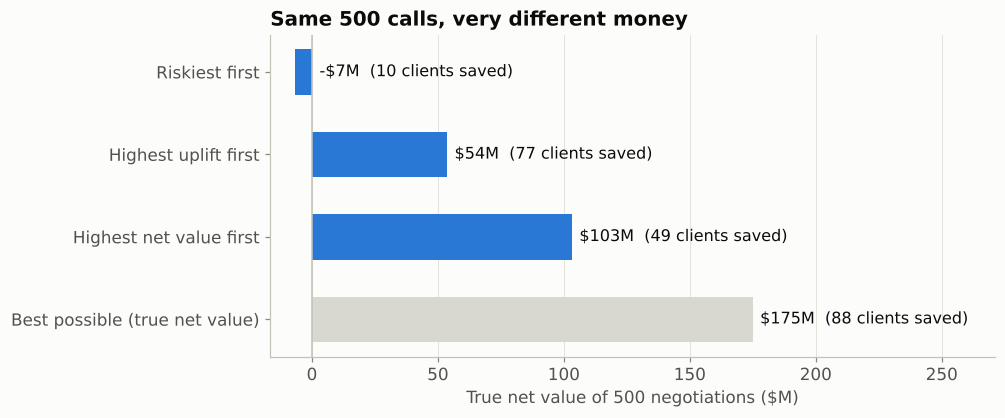

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
names = list(dollars.index)[::-1]
vals = dollars.loc[names, "true net value ($M)"]
colors = [P.BACKGROUND_POINTS if n.startswith("Best") else P.BLUE for n in names]
bars = ax.barh(names, vals, color=colors, height=0.55)
ax.axvline(0, color=P.BASELINE, linewidth=1)
for b, v, n in zip(bars, vals, names):
    saved = dollars.loc[n, "expected clients saved"]
    x = max(v, 0) + 3   # negative bars get their label to the right of zero
    ax.text(x, b.get_y() + b.get_height() / 2, f"{'-' if v < 0 else ''}${abs(v):,.0f}M  ({saved:.0f} clients saved)",
            va="center", ha="left", color=P.INK, fontsize=10.5)
ax.set_xlim(min(vals.min(), 0) - 10, vals.max() * 1.55)
ax.set_xlabel("True net value of 500 negotiations ($M)")
ax.grid(axis="y", visible=False)
ax.set_title("Same 500 calls, very different money")
P.save(fig, "07_dollars_by_rule")
plt.show()

- **Riskiest first loses money.** It calls lost causes and gives concessions to large clients who were leaving anyway or never leaving.
- **Highest uplift first** makes money, by saving the most clients.
- **Highest net value first** saves *fewer* clients than the uplift list, but makes roughly **twice the money**, because it points RMs at the clients where the saved revenue is large and the concession is worth paying.

Revenue enters **after** the uplift model, not inside it. The model answers *does pricing change this client's churn, and by how much?*; the formula answers *what is that worth?* Keeping them apart keeps each step checkable.

## 4. The profit curve, and an honest warning

Walk down the net-value ranking and add up the value. The curve rises, peaks, then falls once the clients being added cost more than they save. Two versions are shown: what the **model expects**, and what **truly** happens.

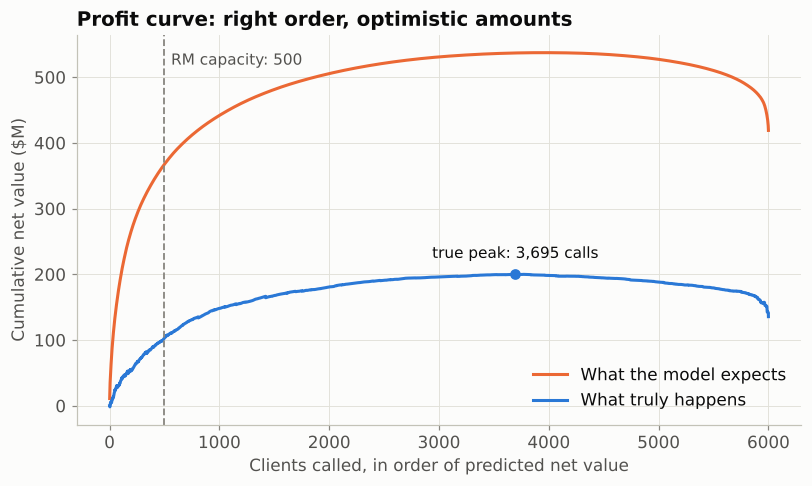

First 500 calls: model expects $368M, truth is $103M


In [5]:
curve = profit_curve(cand, "pred_net_value", "pred_net_value").assign(
    true_value=profit_curve(cand, "pred_net_value", "true_net_value")["cumulative_value"])

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(curve["clients_called"], curve["cumulative_value"] / 1e6, color=P.ORANGE,
        label="What the model expects")
ax.plot(curve["clients_called"], curve["true_value"] / 1e6, color=P.BLUE, label="What truly happens")
ax.axvline(K, color=P.INK_MUTED, linestyle="--", linewidth=1.2)
ax.text(K + 60, ax.get_ylim()[1] * 0.92, "RM capacity: 500", color=P.INK_SECONDARY, fontsize=10)
peak = curve.loc[curve["true_value"].idxmax()]
ax.scatter([peak["clients_called"]], [peak["true_value"] / 1e6], color=P.BLUE, s=36, zorder=3)
ax.text(peak["clients_called"], peak["true_value"] / 1e6 + 25,
        f"true peak: {peak['clients_called']:,.0f} calls", ha="center", color=P.INK, fontsize=10)
ax.set_xlabel("Clients called, in order of predicted net value")
ax.set_ylabel("Cumulative net value ($M)")
ax.legend(loc="lower right")
ax.set_title("Profit curve: right order, optimistic amounts")
P.save(fig, "07_profit_curve")
plt.show()

top = cand[cand["pred_net_value"] > 0].nlargest(K, "pred_net_value")
print(f"First 500 calls: model expects ${top['pred_net_value'].sum() / 1e6:,.0f}M, "
      f"truth is ${top['true_net_value'].sum() / 1e6:,.0f}M")

Two lessons:

- **Capacity binds long before the peak.** Value keeps rising for thousands of calls, so with 500 RM slots every call should go to the top of the net-value list.
- **The model's dollars are too high, several times over.** Part 5 showed the top of an uplift ranking is optimistic. Multiplying by revenue magnifies the error, because a large client with an overestimated uplift produces a large overestimated dollar figure.

A simple correction uses the holdout bins from Part 5: fit a straight line from predicted to actual uplift, and shrink every prediction along it.

In [6]:
test["pred_uplift"] = model.predict_uplift(test)
calibration = fit_uplift_calibration(uplift_by_bin(test, "pred_uplift", 5))
print(f"actual uplift = {calibration[0]:+.3f} + {calibration[1]:.2f} x predicted uplift")

cand["pred_uplift_cal"] = apply_uplift_calibration(cand["pred_uplift"], calibration)
cand["pred_net_value_cal"] = net_value(cand["pred_uplift_cal"], cand["pred_p_churn_pricing"], cand["revenue_at_risk"])
top_cal = cand[cand["pred_net_value_cal"] > 0].nlargest(K, "pred_net_value_cal")
pd.DataFrame({
    "model expects ($M)": [top["pred_net_value"].sum() / 1e6, top_cal["pred_net_value_cal"].sum() / 1e6],
    "truth ($M)": [top["true_net_value"].sum() / 1e6, top_cal["true_net_value"].sum() / 1e6],
}, index=["raw predictions", "calibrated predictions"])

actual uplift = -0.005 + 0.62 x predicted uplift


,model expects ($M),truth ($M)
raw predictions,367.534,103.156
calibrated predictions,185.726,107.771


Calibration removes most of the overstatement while leaving the real value of the list about the same. It does not remove all of it: the clients at the very top are still partly there because their uplift was overestimated. Treat model-based dollar figures as an **upper bound**, and measure the real number with a random holdout (Part 10).

## Takeaways

- **Net value = uplift × revenue at risk − P(stay | pricing) × concession − RM cost.** The concession is paid by everyone who stays, so discounting loyal clients is expensive.
- The highest-uplift client is not always the best call, and the biggest client can be the worst one.
- Ranking by **net value** made about twice the money of ranking by uplift, and calling the riskiest clients first lost money.
- Keep revenue **out of** the uplift model and apply it afterwards; it keeps both steps checkable.
- Model-based dollar estimates are **optimistic**. Calibrate on a holdout and confirm with a random holdout.

**Next, Act 3, Part 8:** everything so far assumed pricing was handed out at random. In a real bank, RMs choose. That one fact breaks the naive comparison, and it is where causal inference begins.